# What Drives the Price of a Car?
**UC Berkeley Professional Certificate in ML/AI · Module 11 · Practical Application II**  
**Audience:** Used-car dealership inventory and pricing managers  
**Framework:** CRISP-DM | **Target:** Advertised listing price (USD)

![CRISP-DM](../images/crisp.png)

> **Interpretation caution:** Listing prices are seller asking prices, not completed transactions. Associations do not establish causal consumer preferences.

## 1. Business Understanding
### 1.1 Determine business objectives
Identify the vehicle characteristics most associated with used-car asking prices, enabling more consistent pricing and inventory decisions.
### 1.2 Assess situation
The supplied Craigslist-derived dataset has noisy prices, missing attributes, and potential duplicate advertisements. Market conditions and seller incentives are not directly observed.
### 1.3 Determine data mining goals
Predict price using available vehicle characteristics; compare regularized linear models; identify robust price associations. **Success:** beat a median-price baseline on a held-out test set using MAE in dollars.
### 1.4 Produce project plan
Audit → clean → visualize → split → preprocess → cross-validate/tune → test → explain → communicate. This notebook documents all six CRISP-DM phases.

## 2. Data Understanding
### 2.1 Collect initial data
Load the provided `vehicles.csv` from the Berkeley starter ZIP.
### 2.2 Describe data
Inspect schema, descriptive statistics and column coverage.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid')
ROOT = Path('..').resolve() if Path('../data/vehicles.csv').exists() else Path('.').resolve()
FIG = ROOT/'outputs'/'figures'; REP = ROOT/'outputs'/'reports'
FIG.mkdir(parents=True,exist_ok=True); REP.mkdir(parents=True,exist_ok=True)
df = pd.read_csv(ROOT/'data'/'vehicles.csv')
print('Original shape:', df.shape)
print('Columns:', ', '.join(df.columns))
display(df.head(3))

Original shape: (426880, 18)
Columns: id, region, price, year, manufacturer, model, condition, cylinders, fuel, odometer, title_status, transmission, VIN, drive, size, type, paint_color, state


,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl


### 2.3 Explore data
Inspect price, mileage, age, manufacturer, and vehicle type. Use distributions and categorical comparisons.
### 2.4 Verify data quality
Record missingness, duplicates, invalid values, and filtering decisions before modeling.

In [2]:
quality = pd.DataFrame({'missing_count':df.isna().sum(),'missing_pct':(100*df.isna().mean()).round(2)})
quality.to_csv(REP/'missing_values.csv')
print('Exact duplicate rows:', df.duplicated().sum())
print('Nonpositive prices:', int((df.price<=0).sum()))
print('Price summary (unfiltered):'); display(df.price.describe(percentiles=[.01,.25,.5,.75,.99]).to_frame())
display(quality.sort_values('missing_pct',ascending=False).head(12))

Exact duplicate rows: 0
Nonpositive prices: 32895
Price summary (unfiltered):


,price
count,4.268800e+05
mean,7.519903e+04
std,1.218228e+07
min,0.000000e+00
1%,0.000000e+00
25%,5.900000e+03
50%,1.395000e+04
75%,2.648575e+04
99%,6.699500e+04
max,3.736929e+09


,missing_count,missing_pct
size,306361,71.77
cylinders,177678,41.62
condition,174104,40.79
VIN,161042,37.73
drive,130567,30.59
paint_color,130203,30.50
type,92858,21.75
manufacturer,17646,4.13
title_status,8242,1.93
model,5277,1.24


## 3. Data Preparation
### 3.1 Select data
Use interpretable listing-time attributes: year, odometer, manufacturer, condition, fuel, transmission, drive, vehicle type, title status, and state. Exclude IDs, VIN, model (very high cardinality), and high-missingness `size`.
### 3.2 Clean data
Remove listings with missing/invalid target, implausible years/mileage, and extreme prices. **These are explicit pragmatic modeling rules, not assertions that every excluded listing is erroneous.**
### 3.3 Construct data
Derive `vehicle_age = 2026 - year` and `mileage_per_year` (diagnostic only); the modeling inputs include age and odometer.
### 3.4 Integrate data
No joins needed: all selected fields are in the provided table.
### 3.5 Format data
Use a train-only imputation/encoding pipeline to prevent leakage.

In [3]:
clean = df.drop_duplicates(subset=['id']).copy()
start_n=len(clean)
mask = (clean.price.between(1000,100000) & clean.year.between(1980,2022) & clean.odometer.between(0,350000))
clean=clean.loc[mask].copy()
clean['vehicle_age'] = 2026-clean['year']
num_features=['vehicle_age','odometer']
cat_features=['manufacturer','condition','fuel','transmission','drive','type','title_status','state']
features=num_features+cat_features
cleaning=pd.DataFrame({'stage':['Raw rows','Unique listing IDs','After price/year/mileage rules'], 'rows':[len(df),start_n,len(clean)]})
cleaning['removed_vs_previous']=cleaning['rows'].shift(1)-cleaning['rows']
cleaning.to_csv(REP/'data_cleaning_summary.csv',index=False)
print('Data retention:',f'{len(clean):,}/{len(df):,}',f'({len(clean)/len(df):.1%})')
display(cleaning)
print('Cleaned median price: $'+format(clean.price.median(),',.0f'))

Data retention: 367,371/426,880 (86.1%)


,stage,rows,removed_vs_previous
0,Raw rows,426880,NaN
1,Unique listing IDs,426880,0.0
2,After price/year/mileage rules,367371,59509.0


Cleaned median price: $15,990


### 3.6 Exploratory visualizations
Charts describe *asking-price associations* in the filtered dataset. They do not measure completed-sale demand.

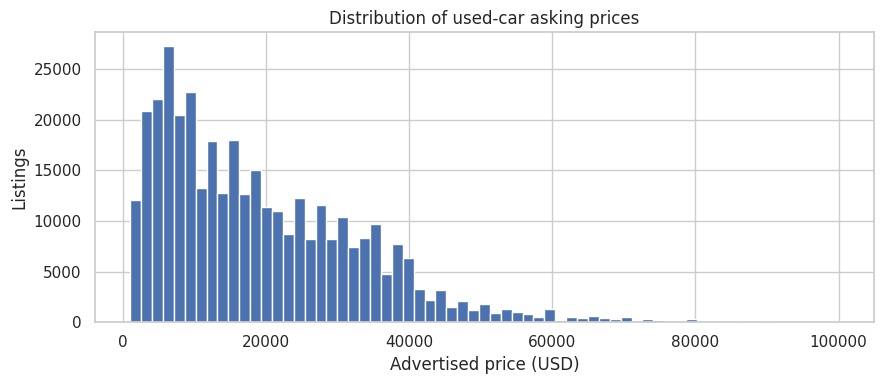

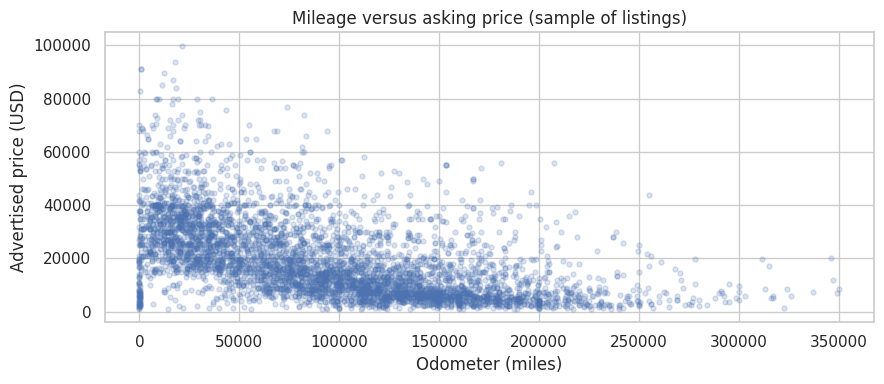

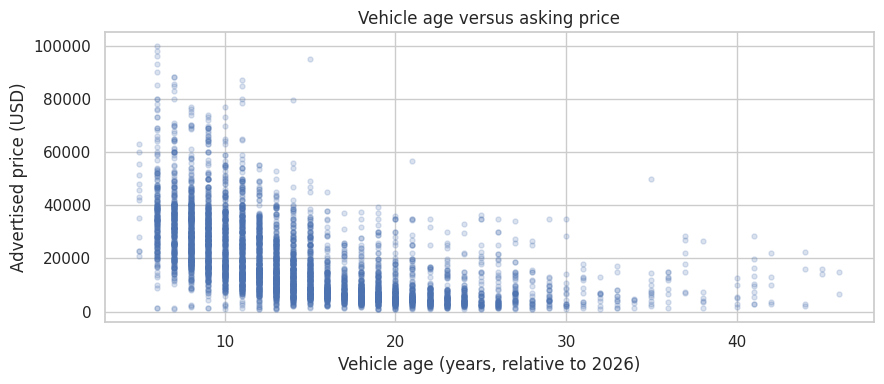

In [4]:
fig,ax=plt.subplots(figsize=(9,4));ax.hist(clean.price,bins=65);ax.set(title='Distribution of used-car asking prices',xlabel='Advertised price (USD)',ylabel='Listings');fig.tight_layout();fig.savefig(FIG/'price_distribution.png',dpi=140);plt.show()
fig,ax=plt.subplots(figsize=(9,4));ax.scatter(clean.sample(min(5000,len(clean)),random_state=42)['odometer'],clean.sample(min(5000,len(clean)),random_state=42)['price'],alpha=.2,s=13);ax.set(title='Mileage versus asking price (sample of listings)',xlabel='Odometer (miles)',ylabel='Advertised price (USD)');fig.tight_layout();fig.savefig(FIG/'price_vs_odometer.png',dpi=140);plt.show()
fig,ax=plt.subplots(figsize=(9,4));ax.scatter(clean.sample(min(5000,len(clean)),random_state=43)['vehicle_age'],clean.sample(min(5000,len(clean)),random_state=43)['price'],alpha=.2,s=13);ax.set(title='Vehicle age versus asking price',xlabel='Vehicle age (years, relative to 2026)',ylabel='Advertised price (USD)');fig.tight_layout();fig.savefig(FIG/'price_by_vehicle_age.png',dpi=140);plt.show()

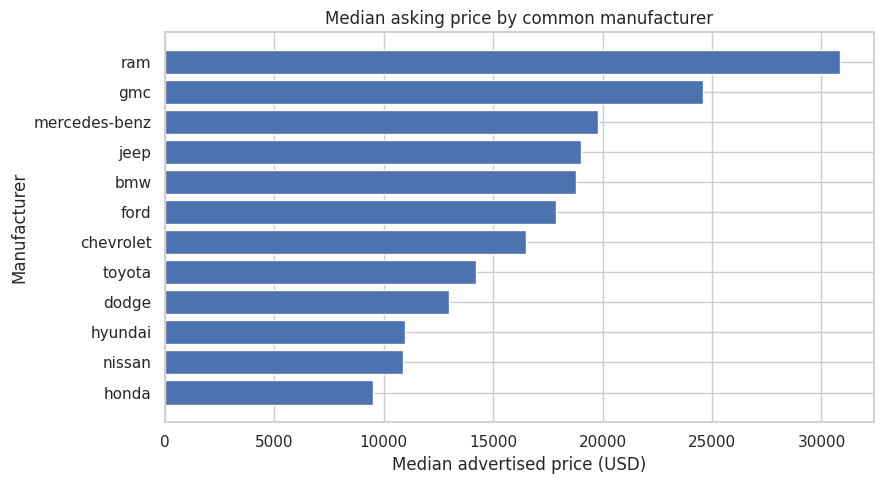

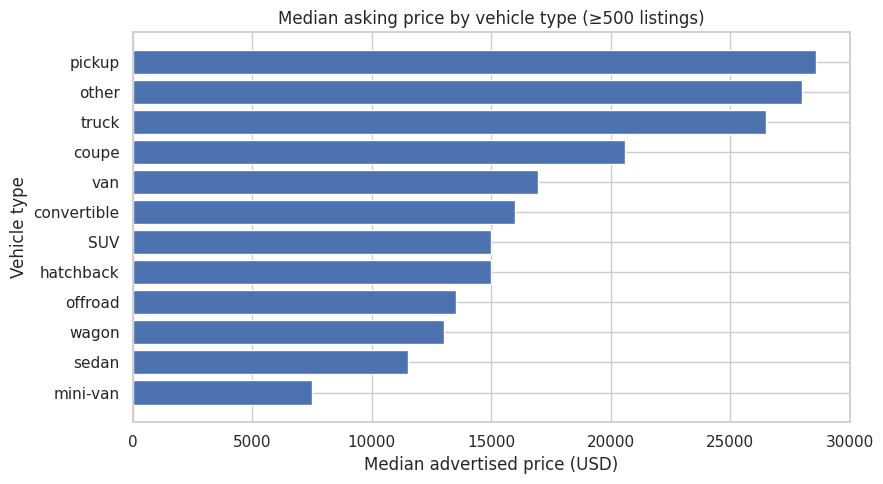

Spearman associations (unadjusted):


,price,odometer,vehicle_age
price,1.000,-0.625,-0.712
odometer,-0.625,1.000,0.701
vehicle_age,-0.712,0.701,1.000


In [5]:
top=clean['manufacturer'].value_counts().head(12).index
man=clean[clean.manufacturer.isin(top)].groupby('manufacturer').agg(median_price=('price','median'),listings=('price','size')).sort_values('median_price')
man.to_csv(REP/'manufacturer_summary.csv')
fig,ax=plt.subplots(figsize=(9,5));ax.barh(man.index,man.median_price);ax.set(title='Median asking price by common manufacturer',xlabel='Median advertised price (USD)',ylabel='Manufacturer');fig.tight_layout();fig.savefig(FIG/'price_by_manufacturer.png',dpi=140);plt.show()
by_type=clean.groupby('type').agg(median_price=('price','median'),listings=('price','size')).query('listings>=500').sort_values('median_price')
by_type.to_csv(REP/'vehicle_type_summary.csv')
fig,ax=plt.subplots(figsize=(9,5));ax.barh(by_type.index,by_type.median_price);ax.set(title='Median asking price by vehicle type (≥500 listings)',xlabel='Median advertised price (USD)',ylabel='Vehicle type');fig.tight_layout();fig.savefig(FIG/'price_by_vehicle_type.png',dpi=140);plt.show()
print('Spearman associations (unadjusted):');display(clean[['price','odometer','vehicle_age']].corr(method='spearman').round(3))

## 4. Modeling
### 4.1 Select modeling techniques
Compare a median baseline, ordinary least squares, Ridge (L2), and Lasso (L1). The objective is price regression, not classification.
### 4.2 Generate test design
Hold out 20% for final evaluation; use 3-fold CV on the entire training set (no sampling). Feature preprocessing is fitted within each training fold. **A random split estimates within-sample generalization, not future-market performance.**
### 4.3 Build models
Tune Ridge and Lasso via `GridSearchCV`; evaluate all models on the same untouched holdout. Use a reproducible capped sample to keep the assignment runnable on a laptop.

In [6]:
model_data=clean.copy()
print(f"Full cleaned modeling population: {len(model_data):,} records (no sampling)")
X=model_data[features];y=model_data['price']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42)
num_pipe=Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
cat_pipe=Pipeline([('imputer',SimpleImputer(strategy='constant',fill_value='Unknown')),('encoder',OneHotEncoder(handle_unknown='ignore',min_frequency=30))])
prep=ColumnTransformer([('numeric',num_pipe,num_features),('categorical',cat_pipe,cat_features)])
cv=KFold(n_splits=3,shuffle=True,random_state=42)
models={'Median baseline':DummyRegressor(strategy='median'), 'Linear Regression':LinearRegression(), 'Ridge':Ridge(), 'Lasso':Lasso(max_iter=1200,tol=.02,selection='random',random_state=42)}
params={'Median baseline':{},'Linear Regression':{},'Ridge':{'model__alpha':[1,10,100]},'Lasso':{'model__alpha':[10,100,500]}}
results=[];fitted={}
for name,estimator in models.items():
    pipe=Pipeline([('preprocess',prep),('model',estimator)])
    if params[name]:
        fit=GridSearchCV(pipe,params[name],cv=cv,scoring='neg_mean_absolute_error',n_jobs=1,refit=True)
    else:
        fit=GridSearchCV(pipe,{},cv=cv,scoring='neg_mean_absolute_error',n_jobs=1,refit=True)
    fit.fit(X_train,y_train)
    pred=fit.predict(X_test)
    results.append({'model':name,'cv_MAE_USD':-fit.best_score_,'test_MAE_USD':mean_absolute_error(y_test,pred),'test_RMSE_USD':np.sqrt(mean_squared_error(y_test,pred)),'test_R2':r2_score(y_test,pred),'best_params':str(fit.best_params_)})
    fitted[name]=fit.best_estimator_
    print(name,'test MAE: $'+format(results[-1]['test_MAE_USD'],',.0f'))
metrics=pd.DataFrame(results).sort_values('test_MAE_USD');metrics.to_csv(REP/'model_performance.csv',index=False)
display(metrics.round(2))

Full cleaned modeling population: 367,371 records (no sampling)


Median baseline test MAE: $11,056


Linear Regression test MAE: $5,667


Ridge test MAE: $5,667


Lasso test MAE: $5,696


,model,cv_MAE_USD,test_MAE_USD,test_RMSE_USD,test_R2,best_params
2,Ridge,5644.09,5667.11,8070.11,0.68,{'model__alpha': 10}
1,Linear Regression,5644.40,5667.36,8069.02,0.68,{}
3,Lasso,5670.45,5696.27,8142.97,0.67,{'model__alpha': 10}
0,Median baseline,11044.78,11055.85,14638.95,-0.06,{}


### 4.4 Assess model
Use held-out MAE (average dollar error) as the primary decision metric; RMSE highlights large errors and R² describes explained variation. Inspect coefficients for direction, while noting categorical reference levels and confounding.

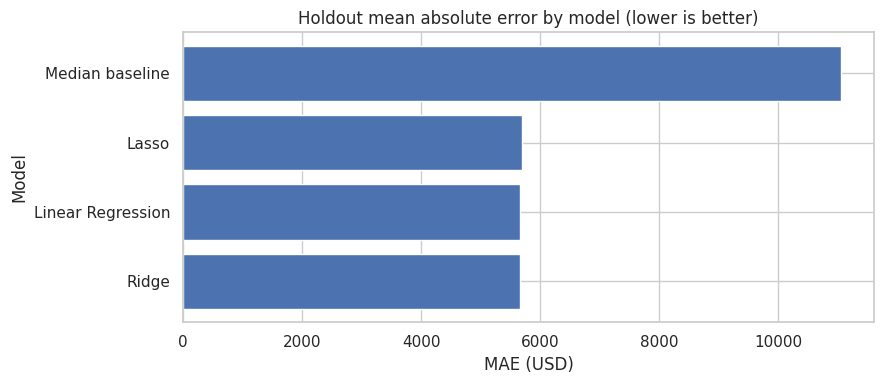

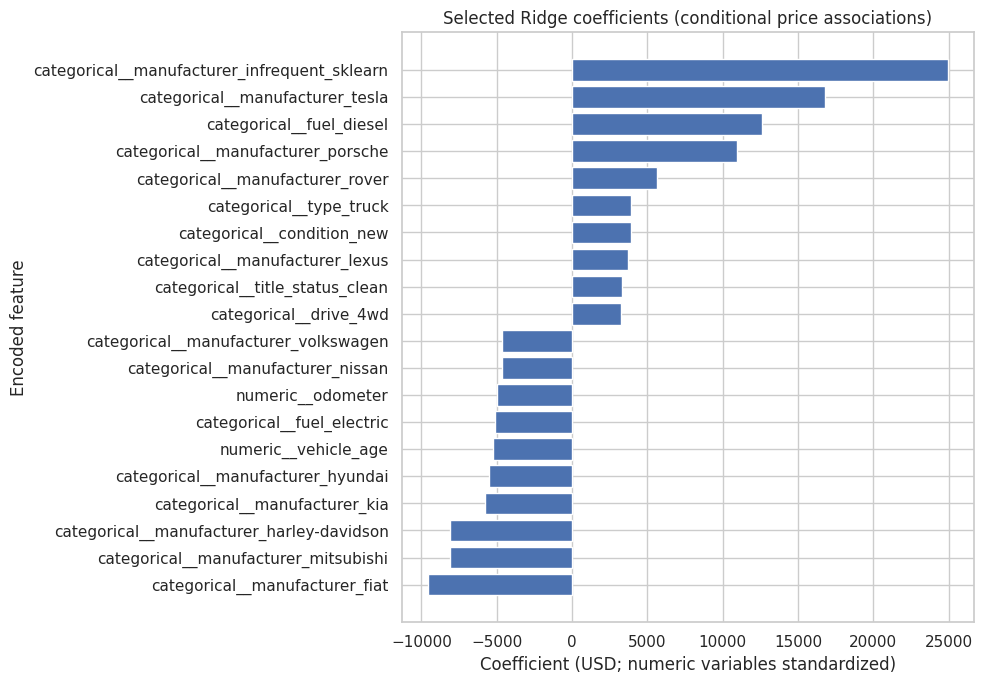

Numeric feature coefficients (per one training SD):


,0
numeric__vehicle_age,-5264.458642
numeric__odometer,-4987.013657


In [7]:
fig,ax=plt.subplots(figsize=(9,4));ax.barh(metrics['model'],metrics['test_MAE_USD']);ax.set(title='Holdout mean absolute error by model (lower is better)',xlabel='MAE (USD)',ylabel='Model');fig.tight_layout();fig.savefig(FIG/'model_comparison.png',dpi=140);plt.show()
linear=fitted['Ridge'];names=linear.named_steps['preprocess'].get_feature_names_out();coef=pd.Series(linear.named_steps['model'].coef_,index=names).sort_values()
coef.rename('coefficient_USD').to_csv(REP/'ridge_coefficients.csv')
strong=pd.concat([coef.head(10),coef.tail(10)]).sort_values()
fig,ax=plt.subplots(figsize=(10,7));ax.barh(strong.index,strong.values);ax.set(title='Selected Ridge coefficients (conditional price associations)',xlabel='Coefficient (USD; numeric variables standardized)',ylabel='Encoded feature');fig.tight_layout();fig.savefig(FIG/'ridge_coefficients.png',dpi=140);plt.show()
print('Numeric feature coefficients (per one training SD):');display(coef[[n for n in coef.index if n.startswith('numeric__')]].to_frame())

## 5. Evaluation
### 5.1 Evaluate results
Compare models with baseline and business interpretability; evaluate whether error magnitude is acceptable for preliminary inventory triage. The model is not a verified transaction-price estimator.
### 5.2 Review process
Audit exclusions, missingness, sampling, potential repeat advertisements, limited categorical representation, lack of transaction outcomes, and possible regional/temporal shifts.
### 5.3 Determine next steps
Validate on newer listings, use sale prices and days-on-lot where available, test region-specific models, and review excluded outliers with dealership specialists.

In [8]:
best=metrics.iloc[0];base=metrics.loc[metrics.model=='Median baseline'].iloc[0]
print(f"Best model: {best['model']} | Holdout MAE ${best['test_MAE_USD']:,.0f} | Baseline MAE ${base['test_MAE_USD']:,.0f}")
print(f"MAE improvement vs baseline: {(1-best['test_MAE_USD']/base['test_MAE_USD']):.1%}")
print(f"Median price of complete cleaned dataset: ${model_data.price.median():,.0f}")
print('Data coverage limitations: condition missing '+f'{df.condition.isna().mean():.1%}'+', size missing '+f'{df['size'].isna().mean():.1%}')
print('Median prices by top manufacturers (descriptive only):');display(man.tail(6))

Best model: Ridge | Holdout MAE $5,667 | Baseline MAE $11,056
MAE improvement vs baseline: 48.7%
Median price of complete cleaned dataset: $15,990
Data coverage limitations: condition missing 40.8%, size missing 71.8%
Median prices by top manufacturers (descriptive only):


,median_price,listings
manufacturer,,
ford,17887.5,60864
bmw,18782.0,13171
jeep,18999.0,16244
mercedes-benz,19800.0,9609
gmc,24590.0,14770
ram,30856.0,15719


## 6. Deployment
### 6.1 Plan deployment
Provide a pricing-assistance dashboard prototype only after external validation; do not automate price-setting from this analysis.
### 6.2 Plan monitoring and maintenance
Monitor price drift, missing data, MAE by vehicle segment and geography, and retrain after material changes.
### 6.3 Produce final report
See the repository README for executive summary, reproducibility, charts, model comparison and dealership recommendations.
### 6.4 Review project
The project demonstrates a complete CRISP-DM cycle; the final output is an evidence-based exploratory pricing report, not a production valuation engine.

**Dealership recommendations:** (1) Use age and mileage in initial pricing checks; (2) benchmark against comparable manufacturer and vehicle type; (3) prioritize collection of condition/title/drive information; (4) use model predictions as a review flag rather than a final price; (5) validate against realized sales before asserting buyer preferences.